## Import Libraries 
Only libraries useful for this project: Matplolib, Pandas, Plotly


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# 1. Prepare Data

## 1.1 Import Data

Read the CSV file containing the real estate data from Mexico city. 

In [52]:
df1 = pd.read_csv("data/mexico-city-real-estate-1.csv")
df1.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",5500000.0,MXN,5450245.50,289775.66,NaN,54.0,NaN,101851.851852,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/o3zb...
1,sell,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",1512000.0,MXN,1498321.97,79661.96,NaN,80.0,NaN,18900.000000,NaN,NaN,NaN,http://iztapalapa.properati.com.mx/q7t0_venta_...
2,sell,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",926667.0,MXN,918284.00,48822.82,NaN,100.0,NaN,9266.670000,NaN,NaN,NaN,http://tlalpan.properati.com.mx/qbi4_venta_dep...
3,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",6410000.0,MXN,6352013.39,337720.36,NaN,135.0,NaN,47481.481481,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/opeq...
4,sell,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.0,USD,16457437.50,875000.00,0.0,263.0,NaN,3326.996198,NaN,NaN,NaN,http://cancun.properati.com.mx/hg4t_venta_depa...


In [53]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4628 entries, 0 to 4627
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   4628 non-null   str    
 1   property_type               4628 non-null   str    
 2   place_with_parent_names     4628 non-null   str    
 3   lat-lon                     4144 non-null   str    
 4   price                       4538 non-null   float64
 5   currency                    4538 non-null   str    
 6   price_aprox_local_currency  4538 non-null   float64
 7   price_aprox_usd             4538 non-null   float64
 8   surface_total_in_m2         1668 non-null   float64
 9   surface_covered_in_m2       4436 non-null   float64
 10  price_usd_per_m2            1150 non-null   float64
 11  price_per_m2                4249 non-null   float64
 12  floor                       291 non-null    float64
 13  rooms                       136 non-null    

## 1.2 Data Cleaning 


### Drop NaN values from the dataframe `df1`



In [54]:
# show sum of NaN values in each column
df1.isnull().sum()

operation                        0
property_type                    0
place_with_parent_names          0
lat-lon                        484
price                           90
currency                        90
price_aprox_local_currency      90
price_aprox_usd                 90
surface_total_in_m2           2960
surface_covered_in_m2          192
price_usd_per_m2              3478
price_per_m2                   379
floor                         4337
rooms                         4492
expenses                      4623
properati_url                    0
dtype: int64

In [55]:
# find percentage of null values in each column
df1.isnull().mean() * 100

operation                      0.000000
property_type                  0.000000
place_with_parent_names        0.000000
lat-lon                       10.458081
price                          1.944685
currency                       1.944685
price_aprox_local_currency     1.944685
price_aprox_usd                1.944685
surface_total_in_m2           63.958513
surface_covered_in_m2          4.148660
price_usd_per_m2              75.151253
price_per_m2                   8.189283
floor                         93.712187
rooms                         97.061366
expenses                      99.891962
properati_url                  0.000000
dtype: float64

- We do not drop every row or column that contains any null value because this would remove several valuable apartment price predictors, especially location (lat-lon) and usable area (surface_covered_in_m2). Instead, we drop columns with extremely high percentage of missing values and columns that create target leakage, we then treat the remaining missing values deliberately.
- In this case, a sensible first pass is to drop:
    - `expenses` — 99.9% missing 
    - `rooms` — 97.1% missing 
    - `floor` — 93.7% missing 
    - `price_usd_per_m2` - 75% missing
    - `surface_total_in_m2` - 64% missing
    - `price_usd_per_m2` and `price_per_m2`— these are calculated from price and area, so they leak information about the target price into the model.
        - A feature is leakage if it contains information that would not be available independently at the time you want to predict a listing’s price. Including leakage variables can make validation metrics look unrealistically strong while hurting real-world generalization
    - `price_aprox_usd`, `price_aprox_local_currency`, and possibly `currency` — if price is the target, these are alternate representations or direct transformations of the target, so they should not be predictors - i.e. we have to choose one price target to focus on and remove the rest:
        - all price columns () have same NaN value percentage at 1.944685, therefore they are similar. Since we will be dealing with USD, we'll keep `price_aprox_usd`
    - `properati_url` — this is just a listing identifier/URL, i.e not a stable property characteristic. Same with `operation`
- We keep `lat-lon` and `surface_covered_in_m2`; both contain important signals for apartment price prediction since geographic location and size of apartment are good predictors of apartment prices. Also, their NaN value percentages are low enough to be acceptable since we can later drop them without affecting the predicting power of the source data.

In [56]:
# drop nan columns and leakage columns

columns_to_drop = [
    'expenses',
    'rooms',
    'floor',
    'price_usd_per_m2',
    'price_per_m2',
    'price_aprox_local_currency',
    'price',
    'currency',
    'surface_total_in_m2',
    'properati_url',
    'operation' 
]

# Drop these columns completely
df1 = df1.drop(columns=columns_to_drop)

df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
1,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",79661.96,80.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0


In [57]:
# investigate the number of remaining NaN values
df1.isnull().sum()

property_type                0
place_with_parent_names      0
lat-lon                    484
price_aprox_usd             90
surface_covered_in_m2      192
dtype: int64

### Filter Apartment Type only

- Since we don't want to arbitrarily remove NaN values, we can further clean the data by focussing on the data we want and then we can later come back to remove any NaN values.
    - We start with focusing on the `property_tupe = apartment` since that is the type of property we will be predicting prices for

In [58]:
mask_aprt_type = df1["property_type"] =="apartment"
df1 = df1[mask_aprt_type]


In [59]:
df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,apartment,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


In [60]:
# Double check there is only one property type = apartment. Then drop the property_type column
df1["property_type"].value_counts()


property_type
apartment    3123
Name: count, dtype: int64

In [61]:
#drop the property_type column
df1.drop(columns=["property_type"], inplace = True)

df1.head()

,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


### Separate `lat-lon` column into two columns `lat` and `lon`

- Since we need precise latitude and longitude, we separate the lat and lon column from `lat-lon` 
- We also ensure that the two columns are of `float` data type

In [ ]:
# Seperate and drop "lat-lon" column
df1[["lat", "lon"]] = df1["lat-lon"].str.split(",", expand = True).astype(float)
df1.drop(columns = ["lat-lon"], inplace = True)

In [63]:
df1.head()

,place_with_parent_names,price_aprox_usd,surface_covered_in_m2,lat,lon
0,|Miguel Hidalgo|Distrito Federal|México|,289775.66,54.0,23.634501,-102.552788
2,|Tlalpan|Distrito Federal|México|,48822.82,100.0,19.279771,-99.234597
3,|Miguel Hidalgo|Distrito Federal|México|,337720.36,135.0,23.634501,-102.552788
4,|Benito Juárez|Quintana Roo|México|,875000.00,263.0,21.190264,-86.819838
5,|Miguel Hidalgo|Distrito Federal|México|,232663.51,87.0,19.432657,-99.177444


### Create Borough column from place_with_parent_names

- We need names of individual boroughs to be able to distinguish the data by borough location rather than the less useful `place_with_parent_names` column
    - the borough name are in the first index
- Ensure to drop the column afterwards

In [64]:
# Create "borough" feature from "place_with_parent_names"
df1["borough"] = df1["place_with_parent_names"].str.split("|", expand = True)[1]
    # [1] grabs the second column of the newly split data (the item right after the first vertical bar) since in Pythn counting starts at 0
df1.drop(columns = ["place_with_parent_names"], inplace = True)

In [67]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
Index: 3123 entries, 0 to 4627
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        3113 non-null   float64
 1   surface_covered_in_m2  2974 non-null   float64
 2   lat                    2801 non-null   float64
 3   lon                    2801 non-null   float64
 4   borough                3123 non-null   str    
dtypes: float64(4), str(1)
memory usage: 146.4 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,borough
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo
2,48822.82,100.0,19.279771,-99.234597,Tlalpan
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo


In [ ]:
# Check for remaining sum of NaN values

df1.isnull().sum() 

price_aprox_usd           10
surface_covered_in_m2    149
lat                      322
lon                      322
borough                    0
dtype: int64

### Remove outliers

- I should have properly done this sooner but, better late than never!
- Real estate data is heavily right-skewed (a few massive penthouses exist, but negative space is impossible), which means symmetric trimming rules like 3-Sigma or fixed 10% cuts will distort data and hurt the machine learning model. Also, in real-world datasets, extreme outliers are often data entry errors. 




Remember we still have NaN values. To further reduce the values lets remove the outliers by trimming the bottom and top 10% of properties in terms of "surface_covered_in_m2".
    - This is important as it helps in reducing the number of false positives/negatives due to imbalanced data. Apartments that are larger or smaller than usual are outliers.
    - Outliers heavily skew both the mean and the standard deviation, meaning any prediction that includes outliers may be biased, we have to remove the top 10
    - 

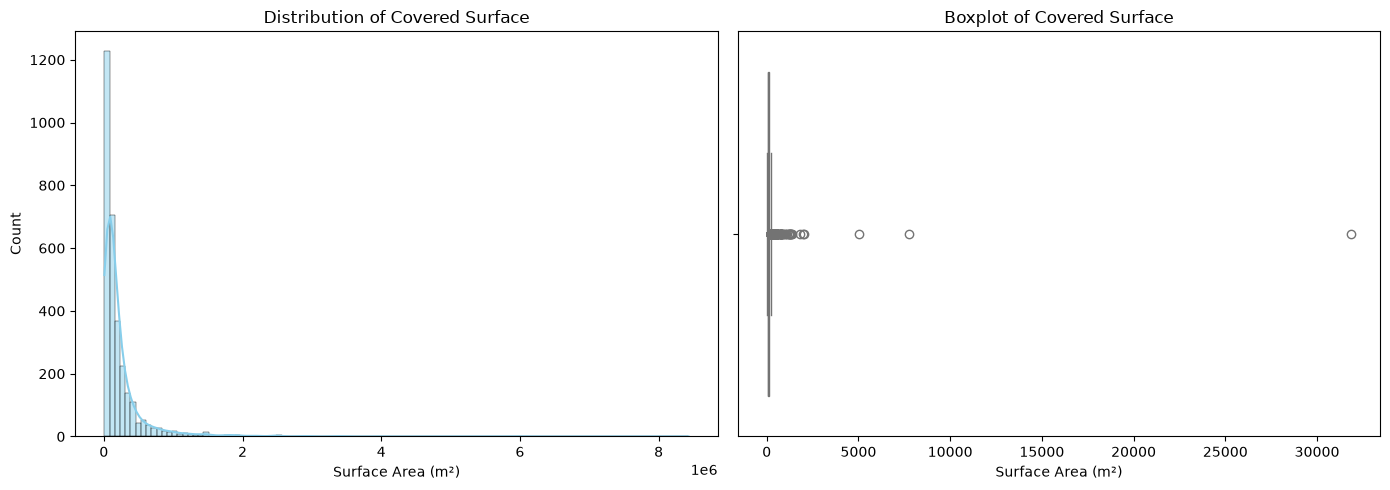

In [83]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram with KDE line
sns.histplot(
    data=df1,
    x="price_aprox_usd",
    kde=True,
    ax=axes[0],
    color="skyblue"
)
axes[0].set_title("Distribution of Covered Surface")
axes[0].set_xlabel("Surface Area (m²)")

# 2. Boxplot to highlight outliers and skewness
sns.boxplot(data=df1, x="surface_covered_in_m2", ax=axes[1], color="lightgreen")
axes[1].set_title("Boxplot of Covered Surface")
axes[1].set_xlabel("Surface Area (m²)")

plt.tight_layout()
plt.show()

In [80]:
print(df1["surface_covered_in_m2"].sort_values(ascending=False))

2081    31840.0
1753     7772.0
1766     5035.0
4301     2016.0
1721     1995.0
         ...   
4466        NaN
4471        NaN
4543        NaN
4622        NaN
4624        NaN
Name: surface_covered_in_m2, Length: 3123, dtype: float64


In [ ]:
# Remove outliers in "surface_covered_in_m2"